# Notebook 4: Error Analysis (run on the laptop, about 2 minutes)

Notebook 3 showed *that* reconstruction-based detection works moderately on IEEE-CIS and barely on BAF.
This notebook looks at *why*, using the seed 0 models:

1. **Where does the reconstruction error come from?** The mean squared error of every feature, for normal and
   fraudulent test transactions, and the share of the total error each feature produces.
2. **Is that where the fraud signal is?** The univariate AUC of every feature (how well that feature alone separates
   fraud from normal) compared with its share of the error.
3. **Which frauds are missed?** Caught and missed frauds at the calibrated threshold, compared on the most
   informative features.

**At a glance**

| | |
|---|---|
| Run on | Laptop (CPU) |
| Run time | About 2 minutes |
| Reads | `../Processed/*.npz`, seed 0 model weights in `../Results/runs_final/`, `thesis_models.py` |
| Writes | Error analysis tables in `../Results/tables/`, `../Figures/error_analysis_signal_vs_error.png` |
| Run order | Step 5 of 6, after Notebook 03. |

In [2]:
import os, sys, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve

sys.path.insert(0, os.getcwd())
import thesis_models as tm

BASE = os.path.abspath("..")
PROC = os.path.join(BASE, "Processed")
RUNS = os.path.join(BASE, "Results", "runs_final")
TAB_DIR = os.path.join(BASE, "Results", "tables")
FIG_DIR = os.path.join(BASE, "Figures")
os.makedirs(TAB_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "font.family": "Times New Roman"})
sns.set_style("whitegrid")
with open(os.path.join(BASE, "Results", "best_latent.json")) as f:
    BEST = json.load(f)
HIDDEN = {"ieee": (256, 128, 64), "baf": (64, 48, 32)}
NAMES = {"ieee": "IEEE-CIS", "baf": "BAF"}

def load_model(ds, kind, n_in, seed=0):
    z = BEST[f"{ds}_{kind}"]
    name = f"{ds}_AE_z{z}_s{seed}" if kind == "AE" else f"{ds}_VAE_b0.01_z{z}_s{seed}"
    m = (tm.AE if kind == "AE" else tm.VAE)(n_in, HIDDEN[ds], z)
    m.load_state_dict(torch.load(os.path.join(RUNS, name, "model.pt"), map_location="cpu"))
    m.eval()
    return m, os.path.join(RUNS, name)

@torch.no_grad()
def per_feature_error(m, X, batch=8192):
    out = []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(X[i:i + batch])
        out.append(((m.reconstruct(xb) - xb) ** 2).numpy())
    return np.concatenate(out)

def threshold(path, y_val):
    sv = np.load(os.path.join(path, "scores_val.npy"))
    p, r, t = precision_recall_curve(y_val, sv)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return t[np.argmax(f1[:-1])]

In [3]:
feat_tabs, miss_tabs, summary = {}, {}, []
for ds in ["ieee", "baf"]:
    d = np.load(os.path.join(PROC, f"{ds}.npz"))
    X, y, names = d["X_test"], d["y_test"], d["feature_names"].astype(str)
    binary = np.array([np.isin(np.unique(d["X_train"][:50000, j]), [0.0, 1.0]).all() for j in range(X.shape[1])])
    signal = np.array([abs(roc_auc_score(y, X[:, j]) - 0.5) + 0.5 if X[:, j].std() > 0 else 0.5
                       for j in range(X.shape[1])])
    for kind in ["AE", "VAE"]:
        m, path = load_model(ds, kind, X.shape[1])
        E = per_feature_error(m, X)
        err_n, err_f = E[y == 0].mean(0), E[y == 1].mean(0)
        tab = pd.DataFrame({"feature": names, "binary": binary, "univariate_auc": signal,
                            "error_share_%": 100 * err_n / err_n.sum(),
                            "mean_error_normal": err_n, "mean_error_fraud": err_f,
                            "fraud_to_normal_error_ratio": err_f / np.clip(err_n, 1e-12, None)})
        feat_tabs[(ds, kind)] = tab
        top_signal = tab.nlargest(10, "univariate_auc")
        summary.append({"dataset": NAMES[ds], "model": kind, "n_features": len(names),
                        "binary_features": int(binary.sum()),
                        "error_share_binary_%": tab.loc[tab.binary, "error_share_%"].sum(),
                        "error_share_top10_signal_features_%": top_signal["error_share_%"].sum(),
                        "error_share_top10_error_features_%": tab.nlargest(10, "error_share_%")["error_share_%"].sum(),
                        "corr_signal_vs_error_ratio": np.corrcoef(tab.univariate_auc, np.log(tab.fraud_to_normal_error_ratio.clip(1e-6)))[0, 1]})
        if kind == "AE":
            thr = threshold(path, d["y_val"])
            score = E.mean(1)
            caught, missed = (y == 1) & (score >= thr), (y == 1) & (score < thr)
            cols = top_signal.feature.head(6).tolist()
            idx = [list(names).index(c) for c in cols]
            miss_tabs[ds] = pd.DataFrame({"normal": X[y == 0][:, idx].mean(0), "caught_fraud": X[caught][:, idx].mean(0),
                                          "missed_fraud": X[missed][:, idx].mean(0)}, index=cols).round(4)
            miss_tabs[ds].loc["count"] = [(y == 0).sum(), caught.sum(), missed.sum()]
    print(NAMES[ds], "done")

summary = pd.DataFrame(summary).round(3)
summary.to_csv(os.path.join(TAB_DIR, "table_error_analysis_summary.csv"), index=False)
summary

IEEE-CIS done
BAF done


,dataset,model,n_features,binary_features,error_share_binary_%,error_share_top10_signal_features_%,error_share_top10_error_features_%,corr_signal_vs_error_ratio
0,IEEE-CIS,AE,419,25,0.167000,0.059000,82.022003,0.104
1,IEEE-CIS,VAE,419,25,0.195000,0.111000,81.380997,0.052
2,BAF,AE,50,32,47.567001,25.264999,68.002998,0.214
3,BAF,VAE,50,32,49.604000,27.506001,71.584999,0.239


**Reading the summary:** if a large share of the error comes from binary features and only a small share from the
features that carry the fraud signal, the reconstruction error is mostly measuring noise that has nothing to do with fraud.

In [5]:
for ds in ["ieee", "baf"]:
    t = feat_tabs[(ds, "AE")]
    print(f"\n{NAMES[ds]} (AE): 10 features with the strongest fraud signal and their share of the error")
    display(t.nlargest(10, "univariate_auc")[["feature", "binary", "univariate_auc", "error_share_%", "fraud_to_normal_error_ratio"]].round(3))
    print(f"{NAMES[ds]} (AE): 10 features that produce the most error")
    display(t.nlargest(10, "error_share_%")[["feature", "binary", "univariate_auc", "error_share_%", "fraud_to_normal_error_ratio"]].round(3))
    t.sort_values("univariate_auc", ascending=False).to_csv(os.path.join(TAB_DIR, f"table_feature_errors_{ds}_AE.csv"), index=False)


IEEE-CIS (AE): 10 features with the strongest fraud signal and their share of the error


,feature,binary,univariate_auc,error_share_%,fraud_to_normal_error_ratio
9,C8,False,0.706,0.000,1.533
378,ProductCD,False,0.704,0.015,1.319
5,C4,False,0.703,0.001,4.595
11,C10,False,0.699,0.000,1.113
332,V303,False,0.687,0.003,0.807
13,C12,False,0.685,0.000,0.399
333,V304,False,0.685,0.003,1.072
331,V302,False,0.684,0.002,1.470
10,C9,False,0.673,0.016,0.430
20,D5,False,0.670,0.018,0.306


IEEE-CIS (AE): 10 features that produce the most error


,feature,binary,univariate_auc,error_share_%,fraud_to_normal_error_ratio
130,V101,False,0.562,15.320,0.000
353,V324,False,0.515,12.280,0.000
352,V323,False,0.515,11.646,0.000
124,V95,False,0.568,10.604,0.000
206,V177,False,0.609,8.433,0.005
351,V322,False,0.512,7.556,0.000
126,V97,False,0.560,5.802,0.001
132,V103,False,0.574,5.702,0.000
172,V143,False,0.512,2.390,0.000
208,V179,False,0.618,2.290,0.005



BAF (AE): 10 features with the strongest fraud signal and their share of the error


,feature,binary,univariate_auc,error_share_%,fraud_to_normal_error_ratio
36,housing_status=BA,True,0.719,1.739,1.212
13,credit_risk_score,False,0.676,0.741,1.799
48,device_os=windows,True,0.661,0.229,1.945
19,proposed_credit_limit,False,0.651,3.190,2.230
3,current_address_months_count,False,0.649,1.899,1.057
0,income,False,0.635,8.011,0.973
4,customer_age,False,0.633,1.046,1.387
22,keep_alive_session,True,0.631,0.380,1.037
15,phone_home_valid,True,0.616,3.168,0.936
1,name_email_similarity,False,0.609,4.861,1.271


BAF (AE): 10 features that produce the most error


,feature,binary,univariate_auc,error_share_%,fraud_to_normal_error_ratio
14,email_is_free,True,0.579,15.923,0.985
10,velocity_4w,False,0.524,13.505,0.952
0,income,False,0.635,8.011,0.973
17,bank_months_count,False,0.544,6.481,0.989
18,has_other_cards,True,0.565,5.240,0.539
1,name_email_similarity,False,0.609,4.861,1.271
9,velocity_24h,False,0.500,4.459,0.924
19,proposed_credit_limit,False,0.651,3.190,2.230
15,phone_home_valid,True,0.616,3.168,0.936
16,phone_mobile_valid,True,0.508,3.165,1.427


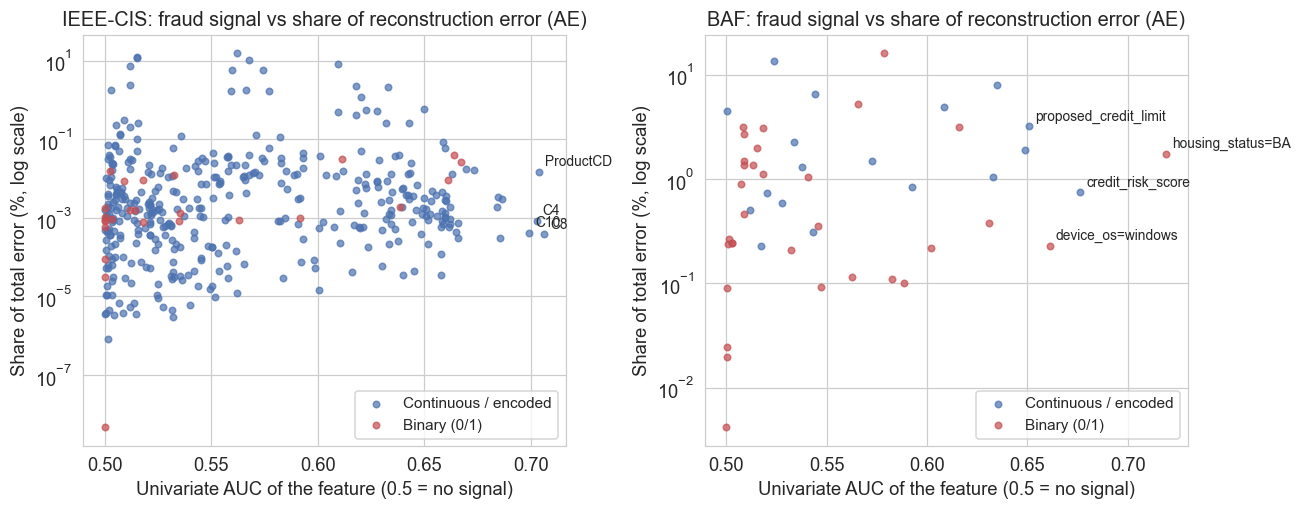

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, ds in zip(axes, ["ieee", "baf"]):
    t = feat_tabs[(ds, "AE")]
    for b, c, lab in [(False, "#4C72B0", "Continuous / encoded"), (True, "#C44E52", "Binary (0/1)")]:
        s = t[t.binary == b]
        ax.scatter(s.univariate_auc, s["error_share_%"], s=18, alpha=0.7, color=c, label=lab)
    for _, r in t.nlargest(4, "univariate_auc").iterrows():
        ax.annotate(r.feature, (r.univariate_auc, r["error_share_%"]), fontsize=9, xytext=(4, 4), textcoords="offset points")
    ax.set_yscale("log")
    ax.set(title=f"{NAMES[ds]}: fraud signal vs share of reconstruction error (AE)",
           xlabel="Univariate AUC of the feature (0.5 = no signal)", ylabel="Share of total error (%, log scale)")
    ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "error_analysis_signal_vs_error.png"), bbox_inches="tight"); plt.show()

## Caught vs missed frauds (AE, seed 0, calibrated threshold)

Mean scaled values of the six most informative features. If missed frauds look like normal transactions on these
features, the model could not have caught them from reconstruction alone.

In [8]:
for ds in ["ieee", "baf"]:
    print(NAMES[ds])
    display(miss_tabs[ds])
    miss_tabs[ds].to_csv(os.path.join(TAB_DIR, f"table_caught_vs_missed_{ds}.csv"))

IEEE-CIS


,normal,caught_fraud,missed_fraud
C8,0.0003,0.0076,0.0009
ProductCD,0.8525,0.2336,0.6151
C4,0.0007,0.0141,0.0007
C10,0.0004,0.0059,0.0006
V303,0.0171,0.0716,0.0295
C12,0.0001,0.0036,0.0009
count,85498.0000,913.0000,2170.0000


BAF


,normal,caught_fraud,missed_fraud
housing_status=BA,0.1916,0.6507,0.3860
credit_risk_score,0.5571,0.6450,0.5840
device_os=windows,0.2549,0.5791,0.5526
proposed_credit_limit,0.1416,0.3388,0.1895
current_address_months_count,0.1661,0.2430,0.1975
income,0.6447,0.7959,0.7149
count,95415.0000,1314.0000,114.0000
